In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_excel("data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [11]:
df.shape

(541909, 8)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [13]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [14]:
df.duplicated().sum()

5268

In [15]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing

,Missing Values,Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [16]:
df[df.duplicated()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


In [17]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [18]:
print("Negative Quantity:",
      (df["Quantity"] < 0).sum())

print("Negative UnitPrice:",
      (df["UnitPrice"] < 0).sum())

print("Zero UnitPrice:",
      (df["UnitPrice"] == 0).sum())

Negative Quantity: 10624
Negative UnitPrice: 2
Zero UnitPrice: 2515


In [ ]:
df_clean = df.copy()

#Remove Exact Duplicates
df_clean = df_clean.drop_duplicates()

print(df_clean.shape)

(536641, 8)


In [21]:
df_clean["Description"].isnull().sum()

1454

In [22]:
df_clean[df_clean["Description"].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [23]:
#Remove rows with missing Description
df_clean = df_clean.dropna(subset=["Description"])
df_clean["Description"].isnull().sum()

0

In [24]:
df_clean["CustomerID"].isnull().sum()

133583

In [27]:
# Display rows with negative Quantity
df_clean[df_clean["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [ ]:
#count the number of INVOICE numbers that start with "C" in the negative rows
negative_rows = df_clean[df_clean["Quantity"] < 0]

negative_rows["InvoiceNo"].astype(str).str.startswith("C").value_counts()

InvoiceNo
True     9251
False     474
Name: count, dtype: int64

In [29]:
df_clean[df_clean["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [30]:
#Remove rows with negative UnitPrice
df_clean = df_clean[df_clean["UnitPrice"] >= 0]
(df_clean["UnitPrice"] < 0).sum()

0

In [31]:
df_clean[df_clean["UnitPrice"] == 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom
13218,537426,84968E,check,-35,2010-12-06 15:36:00,0.0,NaN,United Kingdom
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
14335,537534,85064,CREAM SWEETHEART LETTER RACK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14336,537534,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14337,537534,84692,BOX OF 24 COCKTAIL PARASOLS,2,2010-12-07 11:48:00,0.0,NaN,United Kingdom


In [32]:
#Count the number of rows with UnitPrice equal to 0
df_clean[df_clean["UnitPrice"] == 0]["Description"].value_counts().head(15)

Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
Unsaleable, destroyed.             9
thrown away                        9
FRENCH BLUE METAL DOOR SIGN 1      9
FRENCH BLUE METAL DOOR SIGN 8      8
Found                              8
amazon                             8
FRENCH BLUE METAL DOOR SIGN 4      7
Name: count, dtype: int64

In [33]:
#Create a new DataFrame with only the rows where UnitPrice is greater than 0
df_sales = df_clean[df_clean["UnitPrice"] > 0].copy()

In [34]:
print("Original Dataset:", df.shape)
print("Clean Dataset:", df_clean.shape)
print("Sales Dataset:", df_sales.shape)

Original Dataset: (541909, 8)
Clean Dataset: (535185, 8)
Sales Dataset: (534129, 8)


In [35]:
#Create a new column "TotalSales" in the df_sales DataFrame that is the product of "Quantity" and "UnitPrice"
df_sales["TotalSales"] = (df_sales["Quantity"] * df_sales["UnitPrice"])

In [38]:
df_sales[["InvoiceNo","Description","Quantity","UnitPrice","TotalSales"]].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,TotalSales
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [39]:
# Calculate the total sales per day
daily_sales = df_sales.groupby(df_sales["InvoiceDate"].dt.date)["TotalSales"].sum()

In [42]:
daily_sales.head(10)

InvoiceDate
2010-12-01    58451.56
2010-12-02    46088.32
2010-12-03    45575.38
2010-12-05    30973.63
2010-12-06    53653.87
2010-12-07    44994.70
2010-12-08    44035.22
2010-12-09    52494.14
2010-12-10    57303.01
2010-12-12    17037.50
Name: TotalSales, dtype: float64

In [43]:
print("Number of Days:", len(daily_sales))

Number of Days: 305


In [44]:
print("Start Date:", daily_sales.index.min())
print("End Date:", daily_sales.index.max())

Start Date: 2010-12-01
End Date: 2011-12-09


In [ ]:
# Create a date range from the start date to the end date with a daily frequency
all_dates = pd.date_range(start=daily_sales.index.min(),end=daily_sales.index.max(),freq="D")

missing_dates = all_dates.difference(pd.to_datetime(daily_sales.index))

print("Missing Days:", len(missing_dates))

Missing Days: 69


In [46]:
# Fill in the missing dates with 0 sales
daily_sales = daily_sales.asfreq("D", fill_value=0)

In [47]:
len(daily_sales)

374

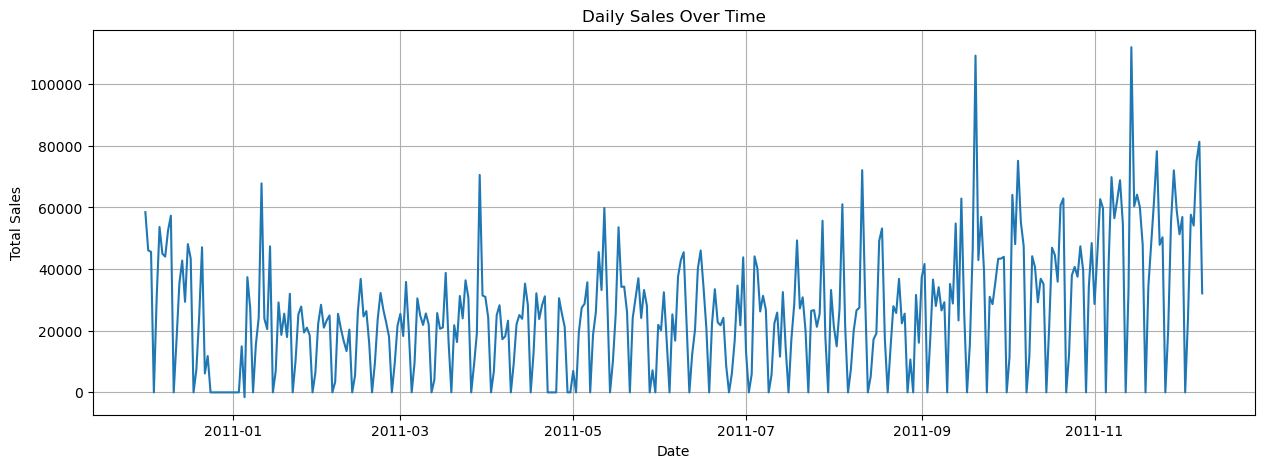

In [48]:
# Plot the daily sales over time
plt.figure(figsize=(15, 5))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.grid(True)
plt.show()

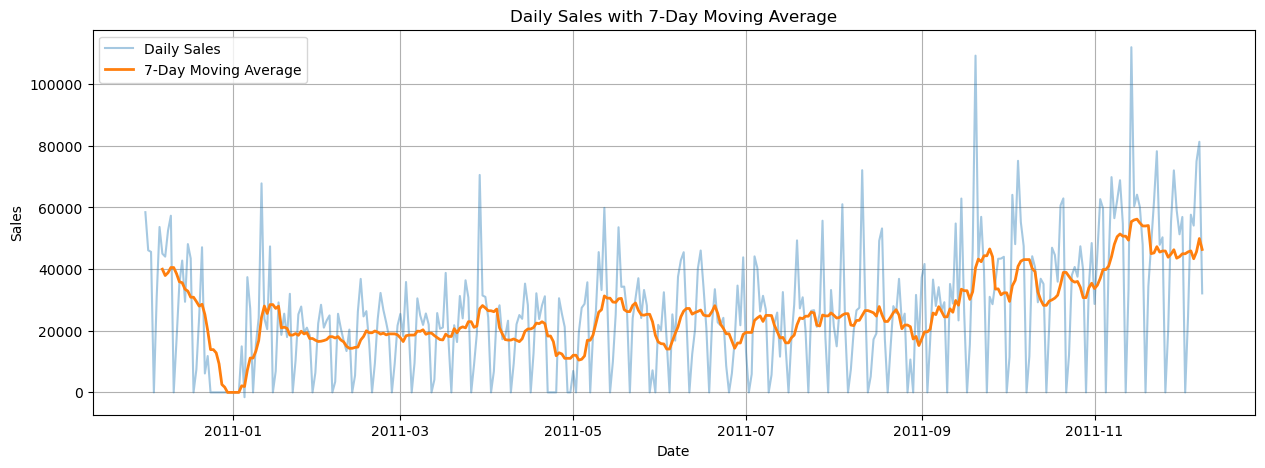

In [49]:
# Calculate the 7-day moving average of daily sales
daily_sales_ma = daily_sales.rolling(window=7).mean()

plt.figure(figsize=(15, 5))

plt.plot(daily_sales.index, daily_sales.values,
         label="Daily Sales", alpha=0.4)

plt.plot(daily_sales_ma.index, daily_sales_ma.values,
         label="7-Day Moving Average", linewidth=2)

plt.title("Daily Sales with 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

In [50]:
daily_sales.describe()

count       374.000000
mean      26064.521588
std       19983.113417
min       -1570.430000
25%       10879.885000
50%       25012.115000
75%       36824.082500
max      111958.620000
Name: TotalSales, dtype: float64

In [51]:
# Count the number of negative sales values
(daily_sales < 0).sum()

1

In [52]:
daily_sales[daily_sales < 0]

InvoiceDate
2011-01-05   -1570.43
Freq: D, Name: TotalSales, dtype: float64

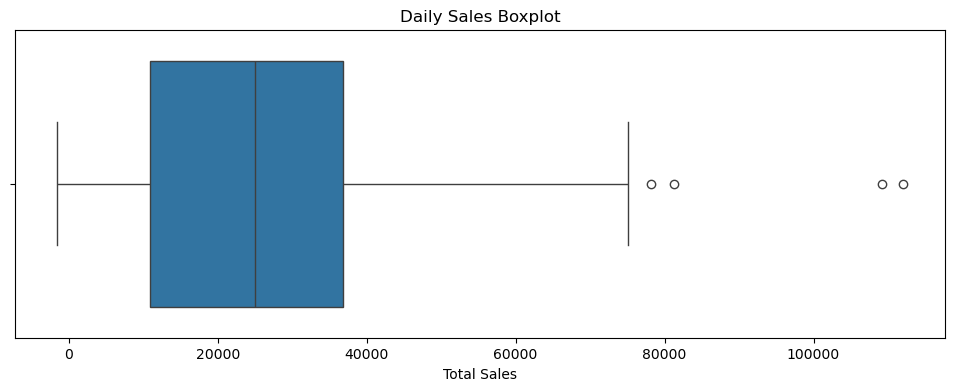

In [53]:
# Plot a boxplot of daily sales
plt.figure(figsize=(12, 4))

sns.boxplot(x=daily_sales)

plt.title("Daily Sales Boxplot")
plt.xlabel("Total Sales")

plt.show()

In [54]:
# Calculate quartiles and IQR
Q1 = daily_sales.quantile(0.25)
Q3 = daily_sales.quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

outliers = daily_sales[daily_sales > upper_limit]

outliers

InvoiceDate
2011-09-20    109228.08
2011-11-14    111958.62
2011-11-23     78223.52
2011-12-08     81294.33
Name: TotalSales, dtype: float64

In [ ]:
# Calculate the monthly sales by resampling the daily sales data to a monthly frequency and summing the sales for each month
monthly_sales = daily_sales.resample("ME").sum()

In [56]:
monthly_sales

InvoiceDate
2010-12-31     746723.610
2011-01-31     558448.560
2011-02-28     497026.410
2011-03-31     682013.980
2011-04-30     492367.841
2011-05-31     722094.100
2011-06-30     689977.230
2011-07-31     680156.991
2011-08-31     703510.580
2011-09-30    1017596.682
2011-10-31    1069368.230
2011-11-30    1456145.800
2011-12-31     432701.060
Freq: ME, Name: TotalSales, dtype: float64

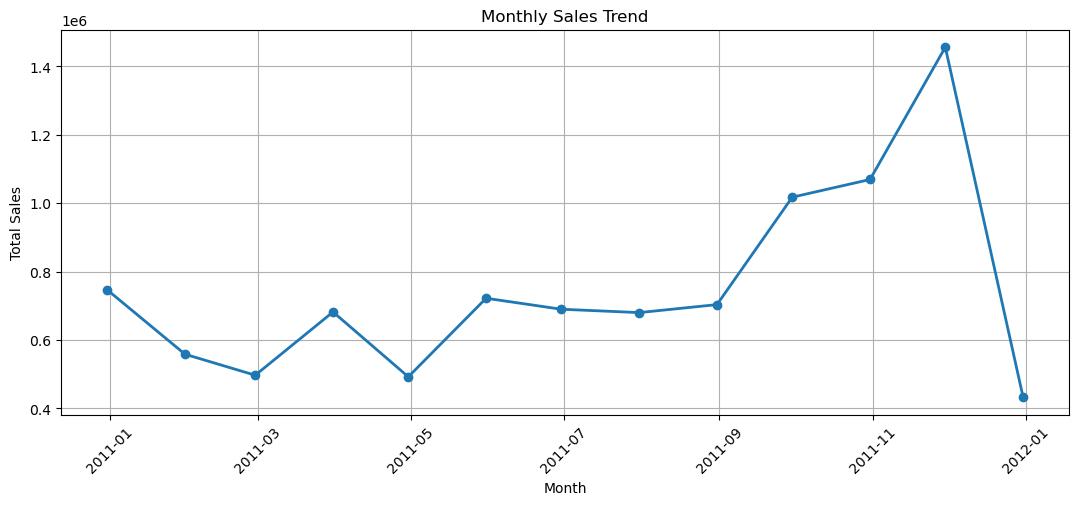

In [57]:
# Plot the monthly sales trend
plt.figure(figsize=(13, 5))

plt.plot(monthly_sales.index, monthly_sales.values,
         marker="o", linewidth=2)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [58]:
# Create a DataFrame with daily sales data and the day of the week
daily_sales_df = daily_sales.reset_index()

daily_sales_df["DayOfWeek"] = (
daily_sales_df["InvoiceDate"].dt.day_name())

In [59]:
# Calculate the average daily sales for each day of the week
daily_sales_df.groupby("DayOfWeek")["TotalSales"].mean()

DayOfWeek
Friday       28890.421130
Monday       29903.684925
Saturday         0.000000
Sunday       15069.046434
Thursday     39050.028333
Tuesday      37088.747377
Wednesday    32038.674630
Name: TotalSales, dtype: float64

In [60]:
# Calculate the total number of days and the number of days with zero sales for each day of the week
daily_sales_df.groupby("DayOfWeek")["TotalSales"].agg(
    Total_Days="count",
    Zero_Sales_Days=lambda x: (x == 0).sum()
)

,Total_Days,Zero_Sales_Days
DayOfWeek,,
Friday,54,4
Monday,53,6
Saturday,53,53
Sunday,53,3
Thursday,54,1
Tuesday,53,1
Wednesday,54,1


In [ ]:
# Calculate the average daily sales for each day of the week, excluding Saturdays
working_days = daily_sales_df[
    daily_sales_df["DayOfWeek"] != "Saturday"
]

working_days.groupby("DayOfWeek")["TotalSales"].mean()

DayOfWeek
Friday       28890.421130
Monday       29903.684925
Sunday       15069.046434
Thursday     39050.028333
Tuesday      37088.747377
Wednesday    32038.674630
Name: TotalSales, dtype: float64

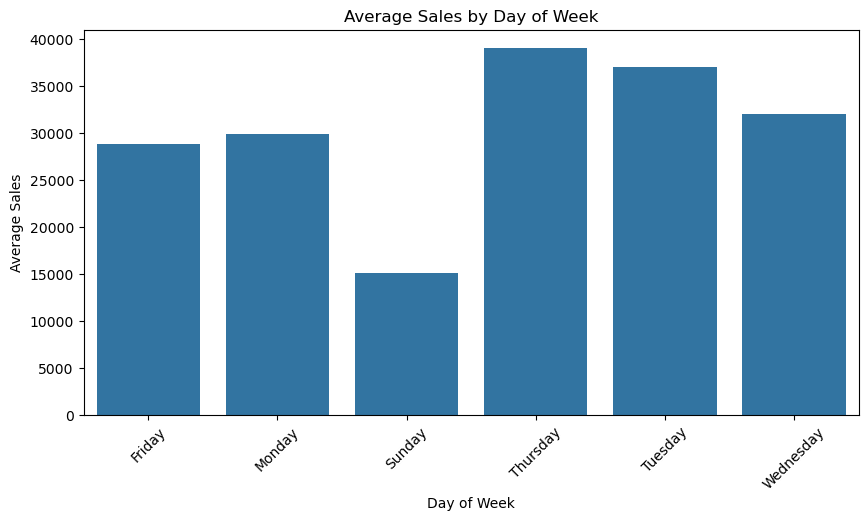

In [62]:
# Plot the average sales by day of the week, excluding Saturdays
plt.figure(figsize=(10, 5))

sns.barplot(
    x=working_days.groupby("DayOfWeek")["TotalSales"].mean().index,
    y=working_days.groupby("DayOfWeek")["TotalSales"].mean().values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.show()

In [63]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [64]:
# Decompose the daily sales time series into trend, seasonal, and residual components
decomposition = seasonal_decompose(daily_sales, model="additive",period=7)

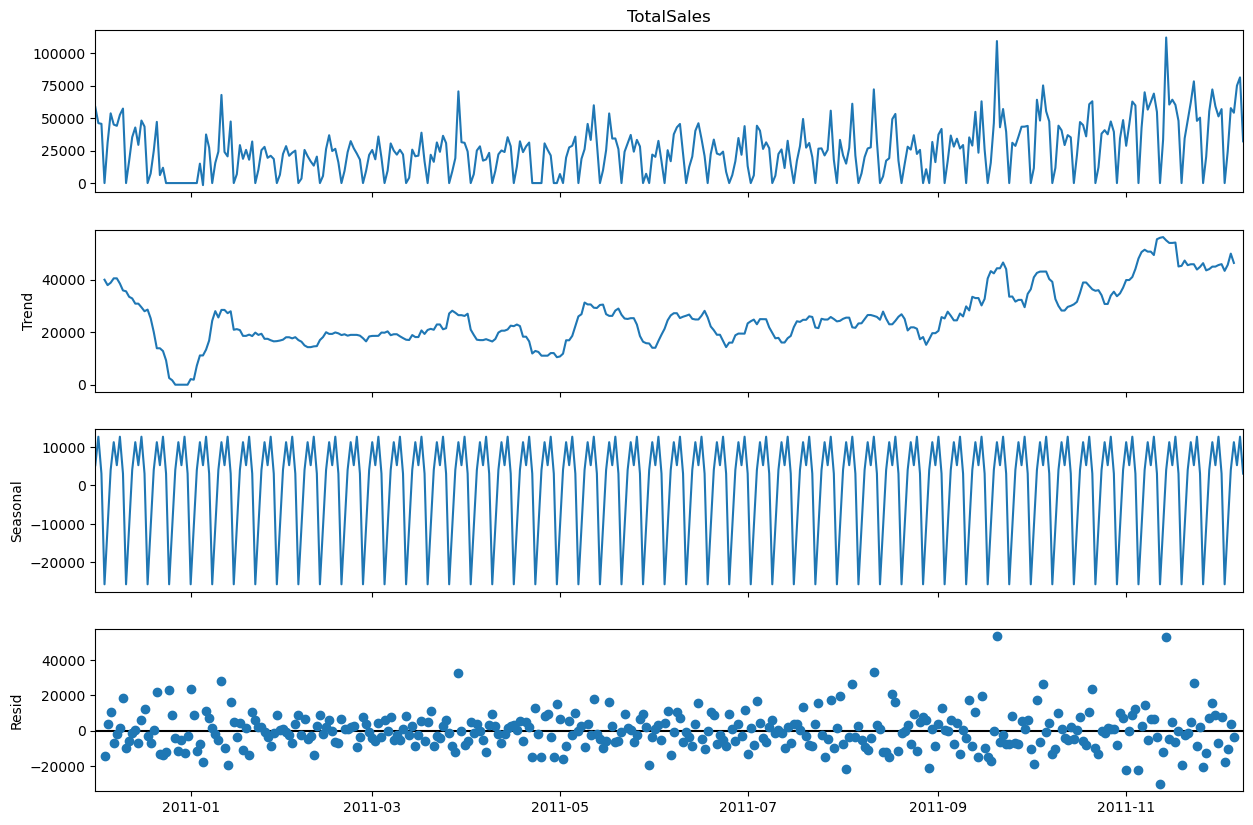

In [65]:
# Plot the decomposition results
fig = decomposition.plot()

fig.set_size_inches(14, 9)

plt.show()

In [66]:
# Analyze the residuals from the decomposition
residuals = decomposition.resid.dropna()

residuals.describe()

count      368.000000
mean       -55.035638
std      10413.742957
min     -30223.888376
25%      -6704.729485
50%       -440.509351
75%       5158.311481
max      53631.799556
Name: resid, dtype: float64

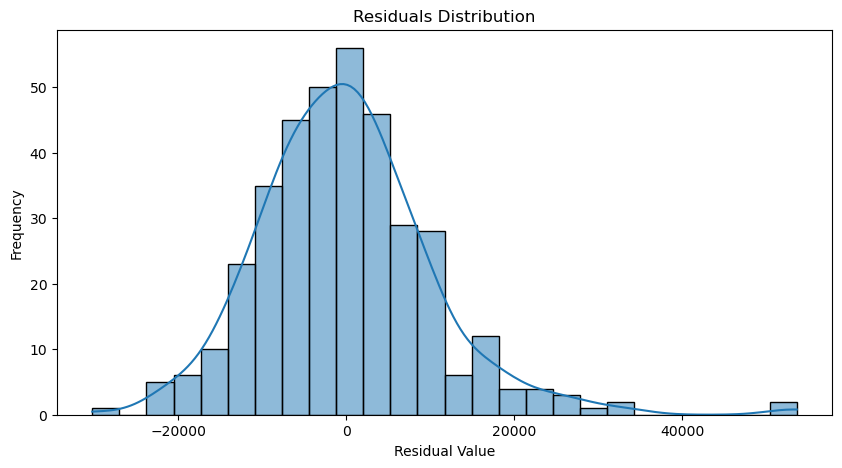

In [67]:
# Plot the distribution of residuals
plt.figure(figsize=(10, 5))

sns.histplot(residuals, kde=True)

plt.title("Residuals Distribution")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")

plt.show()

In [68]:
residuals.skew()

0.9950669859460066

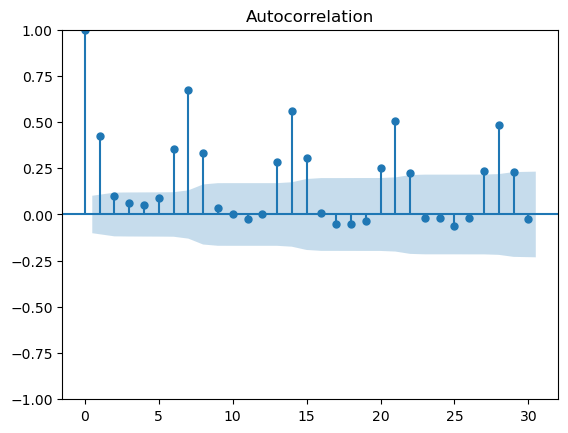

In [69]:
# Plot the autocorrelation of the DAILY sales time series
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(daily_sales, lags=30)
plt.show()

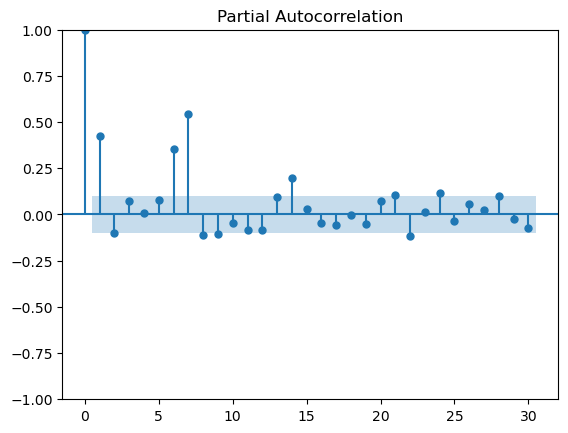

In [70]:
# Plot the partial autocorrelation of the DAILY sales time series
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(daily_sales, lags=30, method="ywm")

plt.show()

In [ ]:
# Prepare the data for modeling by creating a DataFrame with the daily sales and a lagged version of the sales
model_data = daily_sales.to_frame()

model_data["Lag_1"] = daily_sales.shift(1)

In [72]:
model_data.head(10)

,TotalSales,Lag_1
InvoiceDate,,
2010-12-01,58451.56,NaN
2010-12-02,46088.32,58451.56
2010-12-03,45575.38,46088.32
2010-12-04,0.00,45575.38
2010-12-05,30973.63,0.00
2010-12-06,53653.87,30973.63
2010-12-07,44994.70,53653.87
2010-12-08,44035.22,44994.70
2010-12-09,52494.14,44035.22


In [ ]:
# Create additional lag features for the model
model_data["Lag_7"] = daily_sales.shift(7)

In [74]:
model_data.head(12)

,TotalSales,Lag_1,Lag_7
InvoiceDate,,,
2010-12-01,58451.56,NaN,NaN
2010-12-02,46088.32,58451.56,NaN
2010-12-03,45575.38,46088.32,NaN
2010-12-04,0.00,45575.38,NaN
2010-12-05,30973.63,0.00,NaN
2010-12-06,53653.87,30973.63,NaN
2010-12-07,44994.70,53653.87,NaN
2010-12-08,44035.22,44994.70,58451.56
2010-12-09,52494.14,44035.22,46088.32


In [75]:
# Create additional lag features for the model
model_data["Lag_14"] = daily_sales.shift(14)
model_data.head(16)

,TotalSales,Lag_1,Lag_7,Lag_14
InvoiceDate,,,,
2010-12-01,58451.56,NaN,NaN,NaN
2010-12-02,46088.32,58451.56,NaN,NaN
2010-12-03,45575.38,46088.32,NaN,NaN
2010-12-04,0.00,45575.38,NaN,NaN
2010-12-05,30973.63,0.00,NaN,NaN
2010-12-06,53653.87,30973.63,NaN,NaN
2010-12-07,44994.70,53653.87,NaN,NaN
2010-12-08,44035.22,44994.70,58451.56,NaN
2010-12-09,52494.14,44035.22,46088.32,NaN


In [76]:
# Create a new column "DayOfWeek" in the model_data DataFrame that contains the day of the week for each date
model_data["DayOfWeek"] = model_data.index.dayofweek

In [77]:
# Create a new column "Month" in the model_data DataFrame that contains the month for each date
model_data["Month"] = model_data.index.month

In [78]:
# Create a new column "DayOfMonth" in the model_data DataFrame that contains the day of the month for each date
model_data["DayOfMonth"] = model_data.index.day

In [79]:
# Create a new column "IsWeekend" in the model_data DataFrame that indicates whether the day is a weekend (Saturday or Sunday)
model_data["IsWeekend"] = (model_data["DayOfWeek"].isin([5, 6]).astype(int))

In [80]:
model_data.head(16)

,TotalSales,Lag_1,Lag_7,Lag_14,DayOfWeek,Month,DayOfMonth,IsWeekend
InvoiceDate,,,,,,,,
2010-12-01,58451.56,NaN,NaN,NaN,2,12,1,0
2010-12-02,46088.32,58451.56,NaN,NaN,3,12,2,0
2010-12-03,45575.38,46088.32,NaN,NaN,4,12,3,0
2010-12-04,0.00,45575.38,NaN,NaN,5,12,4,1
2010-12-05,30973.63,0.00,NaN,NaN,6,12,5,1
2010-12-06,53653.87,30973.63,NaN,NaN,0,12,6,0
2010-12-07,44994.70,53653.87,NaN,NaN,1,12,7,0
2010-12-08,44035.22,44994.70,58451.56,NaN,2,12,8,0
2010-12-09,52494.14,44035.22,46088.32,NaN,3,12,9,0


In [81]:
# Create a new column "Rolling_Mean_7" in the model_data DataFrame that contains the 7-day rolling mean of daily sales, shifted by 1 day to avoid data leakage
model_data["Rolling_Mean_7"] = (daily_sales.shift(1).rolling(window=7).mean())

In [82]:
# Create a new column "Rolling_Std_7" in the model_data DataFrame that contains the 7-day rolling standard deviation of daily sales, shifted by 1 day to avoid data leakage
model_data["Rolling_Std_7"] = (daily_sales.shift(1).rolling(window=7).std())

In [83]:
model_data.head(20)

,TotalSales,Lag_1,Lag_7,Lag_14,DayOfWeek,Month,DayOfMonth,IsWeekend,Rolling_Mean_7,Rolling_Std_7
InvoiceDate,,,,,,,,,,
2010-12-01,58451.56,NaN,NaN,NaN,2,12,1,0,NaN,NaN
2010-12-02,46088.32,58451.56,NaN,NaN,3,12,2,0,NaN,NaN
2010-12-03,45575.38,46088.32,NaN,NaN,4,12,3,0,NaN,NaN
2010-12-04,0.00,45575.38,NaN,NaN,5,12,4,1,NaN,NaN
2010-12-05,30973.63,0.00,NaN,NaN,6,12,5,1,NaN,NaN
2010-12-06,53653.87,30973.63,NaN,NaN,0,12,6,0,NaN,NaN
2010-12-07,44994.70,53653.87,NaN,NaN,1,12,7,0,NaN,NaN
2010-12-08,44035.22,44994.70,58451.56,NaN,2,12,8,0,39962.494286,19585.084766
2010-12-09,52494.14,44035.22,46088.32,NaN,3,12,9,0,37903.017143,18011.592067


In [84]:
model_data.isnull().sum()

TotalSales         0
Lag_1              1
Lag_7              7
Lag_14            14
DayOfWeek          0
Month              0
DayOfMonth         0
IsWeekend          0
Rolling_Mean_7     7
Rolling_Std_7      7
dtype: int64

In [85]:
model_data = model_data.dropna().copy()

model_data.shape

(360, 10)

In [86]:
model_data.isnull().sum()

TotalSales        0
Lag_1             0
Lag_7             0
Lag_14            0
DayOfWeek         0
Month             0
DayOfMonth        0
IsWeekend         0
Rolling_Mean_7    0
Rolling_Std_7     0
dtype: int64

# Train Test Split

In [87]:
# Sort the model_data DataFrame by its index (date) to ensure that the data is in chronological order before splitting into training and testing sets
model_data = model_data.sort_index()

split_point = int(len(model_data) * 0.8)

train_data = model_data.iloc[:split_point]
test_data = model_data.iloc[split_point:]

print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (288, 10)
Testing Data: (72, 10)


In [88]:
# Prepare the features (X) and target variable (y) for both training and testing datasets
X_train = train_data.drop("TotalSales", axis=1)
y_train = train_data["TotalSales"]

X_test = test_data.drop("TotalSales", axis=1)
y_test = test_data["TotalSales"]

In [89]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (288, 9)
y_train: (288,)
X_test: (72, 9)
y_test: (72,)


# ML Models

In [ ]:
# 1)Linear Regression Model
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

In [91]:
# Fit the linear regression model to the training data and make predictions on the test data
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)


In [92]:
comparison = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
InvoiceDate,,
2011-09-29,43406.23,38786.605817
2011-09-30,43982.85,33062.768306
2011-10-01,0.00,11805.347729
2011-10-02,11520.61,20873.988951
2011-10-03,64081.90,33272.151941
2011-10-04,48082.73,38485.541448
2011-10-05,75111.57,40285.042812
2011-10-06,55177.01,42714.896237
2011-10-07,47441.27,44042.082796


In [93]:
# Evaluate the model's performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 12898.358983824462
RMSE: 16638.77209515036


In [94]:
# 2) Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100,random_state=42)

rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [95]:
rf_pred = rf_model.predict(X_test)

In [96]:
# Evaluate the Random Forest model's performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 12457.026194861113
Random Forest RMSE: 17553.372599501898


In [97]:
# Evaluate the models using R-squared (R2) score
from sklearn.metrics import r2_score

lr_r2 = r2_score(y_test, y_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Linear Regression R2:", lr_r2)
print("Random Forest R2:", rf_r2)

Linear Regression R2: 0.5109506123361476
Random Forest R2: 0.4557087956526694


In [118]:
# 3) Neural Network Regressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

nn_model = Pipeline([
("scaler", StandardScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=1000,
        random_state=42
    ))
])

In [119]:
# Fit the neural network model to the training data and make predictions on the test data
nn_model.fit(X_train, y_train)
nn_pred = nn_model.predict(X_test)

c:\Users\alamia\anaconda3\envs\kmedoids_env\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [120]:
# Evaluate the neural network model's performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
nn_mae = mean_absolute_error(y_test, nn_pred)
nn_rmse = np.sqrt(mean_squared_error(y_test, nn_pred))
nn_r2 = r2_score(y_test, nn_pred)

print("Neural Network MAE:", nn_mae)
print("Neural Network RMSE:", nn_rmse)
print("Neural Network R2:", nn_r2)

Neural Network MAE: 11972.55537645296
Neural Network RMSE: 16224.45755531011
Neural Network R2: 0.5350025787890706


In [102]:
import xgboost as xgb

print("XGBoost Version:", xgb.__version__)

XGBoost Version: 3.2.0


In [103]:
#4) XGBoost Regressor
xgb_model = xgb.XGBRegressor(n_estimators=300,learning_rate=0.05,max_depth=4,random_state=42,objective="reg:squarederror")

In [104]:
# Fit the XGBoost model to the training data and make predictions on the test data
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

In [105]:
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 14325.005320483315
XGBoost RMSE: 19920.521915929352
XGBoost R2: 0.29901036153822613


In [106]:
# Create a DataFrame to compare the performance of all models
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Neural Network",
        "XGBoost"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, rf_pred),
        nn_mae,
        xgb_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        nn_rmse,
        xgb_rmse
    ],
    "R2 Score": [
        lr_r2,
        rf_r2,
        nn_r2,
        xgb_r2
    ]
})

results.sort_values(by="MAE")

,Model,MAE,RMSE,R2 Score
2,Neural Network,11972.555376,16224.457555,0.535003
1,Random Forest,12457.026195,17553.372600,0.455709
0,Linear Regression,12898.358984,16638.772095,0.510951
3,XGBoost,14325.005320,19920.521916,0.299010


### Model Evaluation & Best Model Selection

After evaluating four different Machine Learning models using MAE, RMSE, and R² Score, the results show that **Neural Network (MLPRegressor)** achieved the best overall performance.

It obtained the following results:

- **MAE:** 11,972.56
- **RMSE:** 16,224.46
- **R² Score:** 0.535

Compared to the other models, Neural Network achieved the lowest MAE and RMSE, along with the highest R² Score.

Therefore, Neural Network was selected as the best-performing model among the four tested models for the Sales Forecasting task.

Further evaluation and optimization will be performed before using it for future sales predictions.

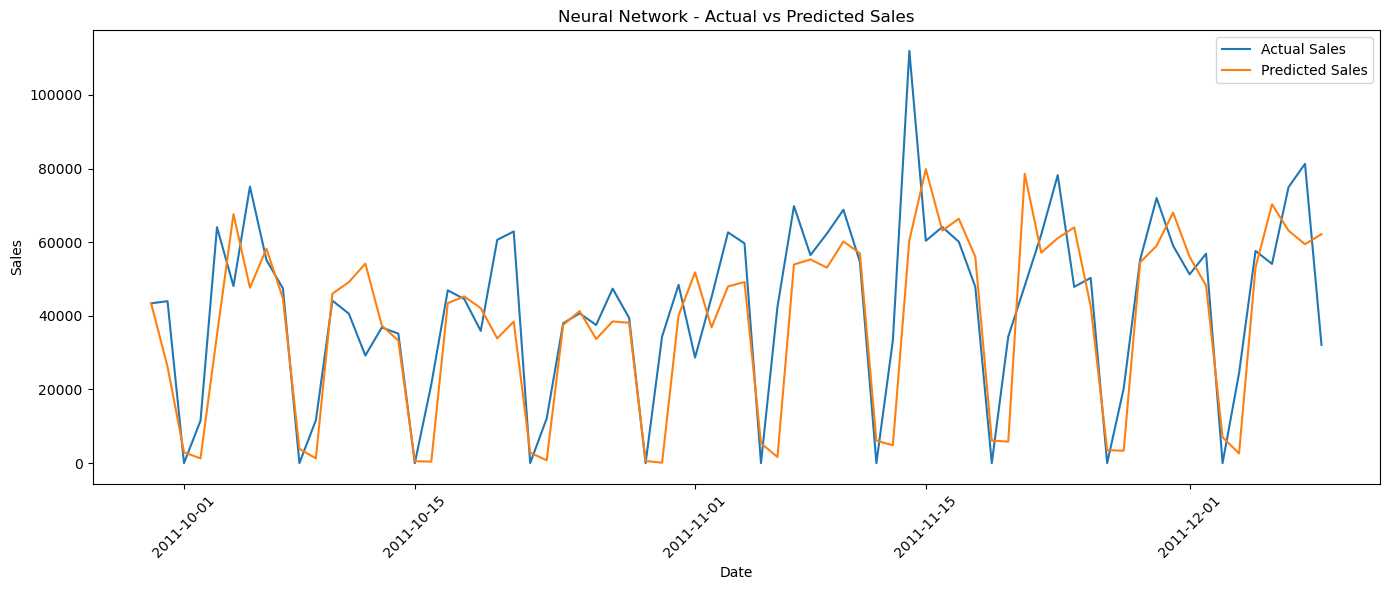

In [107]:
# Plot the actual vs predicted sales for the Neural Network model
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test, label="Actual Sales")
plt.plot(y_test.index, nn_pred, label="Predicted Sales")

plt.title("Neural Network - Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [108]:
residuals = y_test - nn_pred

print("Residuals Summary:")
print(residuals.describe())

Residuals Summary:
count       72.000000
mean      4449.377239
std      15711.929930
min     -30411.366777
25%      -4073.865174
50%       1609.396208
75%      12079.472147
max      51420.796750
Name: TotalSales, dtype: float64


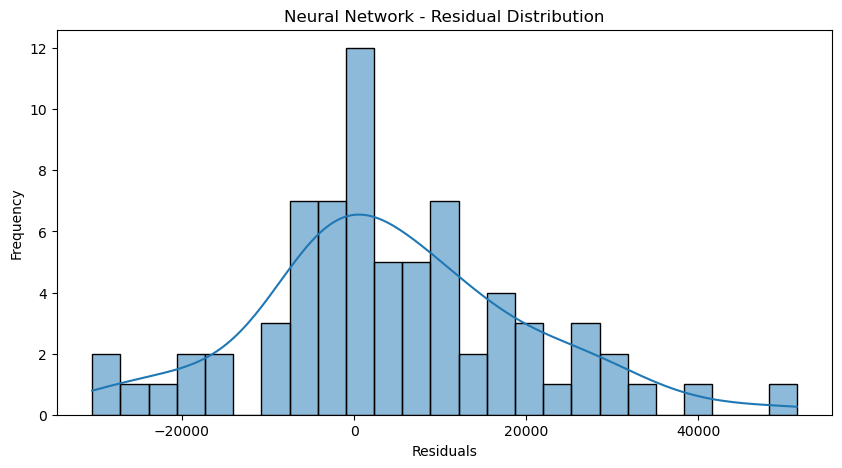

In [109]:
# Plot the distribution of residuals for the Neural Network model
plt.figure(figsize=(10, 5))

sns.histplot(residuals, bins=25, kde=True)

plt.title("Neural Network - Residual Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

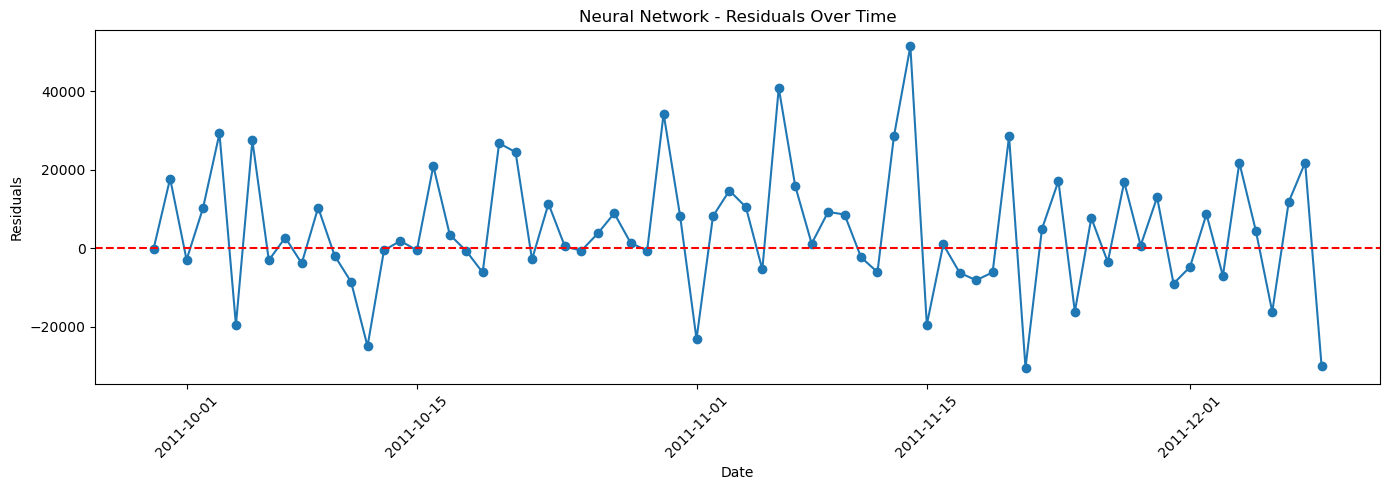

In [110]:
# Plot the residuals over time for the Neural Network model
plt.figure(figsize=(14, 5))

plt.plot(residuals.index, residuals, marker="o")
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Neural Network - Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [121]:
import joblib

joblib.dump(nn_model, "best_sales_model.pkl")

['best_sales_model.pkl']

In [122]:
#forecast future sales using the best model (Neural Network) for the next 30 days
forecast_data = daily_sales.copy()

last_date = forecast_data.index.max()

print("Last Available Date:", last_date)
print("Last 14 Days Sales:")
print(forecast_data.tail(14))

Last Available Date: 2011-12-09 00:00:00
Last 14 Days Sales:
InvoiceDate
2011-11-26        0.00
2011-11-27    20239.79
2011-11-28    55242.56
2011-11-29    72008.09
2011-11-30    59049.59
2011-12-01    51282.33
2011-12-02    56898.47
2011-12-03        0.00
2011-12-04    24421.82
2011-12-05    57630.20
2011-12-06    54109.39
2011-12-07    74952.61
2011-12-08    81294.33
2011-12-09    32111.91
Freq: D, Name: TotalSales, dtype: float64


In [123]:
# Create a DataFrame to hold the forecasted sales for the next 30 days
next_date = last_date + pd.Timedelta(days=1)

next_features = pd.DataFrame({
    "Lag_1": [forecast_data.iloc[-1]],
    "Lag_7": [forecast_data.iloc[-7]],
    "Lag_14": [forecast_data.iloc[-14]],
    "DayOfWeek": [next_date.dayofweek],
    "Month": [next_date.month],
    "DayOfMonth": [next_date.day],
    "IsWeekend": [int(next_date.dayofweek in [5, 6])],
    "Rolling_Mean_7": [forecast_data.iloc[-7:].mean()],
    "Rolling_Std_7": [forecast_data.iloc[-7:].std()]
}, index=[next_date])

next_features

,Lag_1,Lag_7,Lag_14,DayOfWeek,Month,DayOfMonth,IsWeekend,Rolling_Mean_7,Rolling_Std_7
2011-12-10,32111.91,0.0,0.0,5,12,10,1,46360.037143,29036.059831


In [124]:
# Use the trained Neural Network model to predict sales for the next day
first_prediction = nn_model.predict(next_features)

print("Forecast Date:", next_date.date())
print("Predicted Sales:", first_prediction[0])

Forecast Date: 2011-12-10
Predicted Sales: 2739.8258842482464


In [125]:
# Check if the next date is a Saturday (dayofweek == 5) and set the forecast value to 0 if it is, otherwise use the predicted sales value
forecast_value = 0 if next_date.dayofweek == 5 else float(first_prediction[0])

forecast_data.loc[next_date] = forecast_value

print("Final Forecast:", forecast_value)
print("Updated Forecast Data:")
print(forecast_data.tail())

Final Forecast: 0
Updated Forecast Data:
InvoiceDate
2011-12-06    54109.39
2011-12-07    74952.61
2011-12-08    81294.33
2011-12-09    32111.91
2011-12-10        0.00
Freq: D, Name: TotalSales, dtype: float64


In [126]:
# Create a DataFrame to hold the forecasted sales for the next 30 days
future_forecasts = []

for i in range(29):

    next_date = forecast_data.index.max() + pd.Timedelta(days=1)

    next_features = pd.DataFrame({
        "Lag_1": [forecast_data.iloc[-1]],
        "Lag_7": [forecast_data.iloc[-7]],
        "Lag_14": [forecast_data.iloc[-14]],
        "DayOfWeek": [next_date.dayofweek],
        "Month": [next_date.month],
        "DayOfMonth": [next_date.day],
        "IsWeekend": [int(next_date.dayofweek in [5, 6])],
        "Rolling_Mean_7": [forecast_data.iloc[-7:].mean()],
        "Rolling_Std_7": [forecast_data.iloc[-7:].std()]
    }, index=[next_date])

    prediction = nn_model.predict(next_features)[0]

    forecast_value = 0 if next_date.dayofweek == 5 else float(prediction)

    forecast_data.loc[next_date] = forecast_value

    future_forecasts.append({
        "Date": next_date,
        "Predicted_Sales": forecast_value
    })

future_forecast = pd.DataFrame(future_forecasts)

future_forecast

,Date,Predicted_Sales
0,2011-12-11,2059.722096
1,2011-12-12,44624.053764
2,2011-12-13,57264.723680
3,2011-12-14,62767.160966
4,2011-12-15,61077.448352
5,2011-12-16,41038.713697
6,2011-12-17,0.000000
7,2011-12-18,759.934411
8,2011-12-19,36435.534858
9,2011-12-20,48389.525821


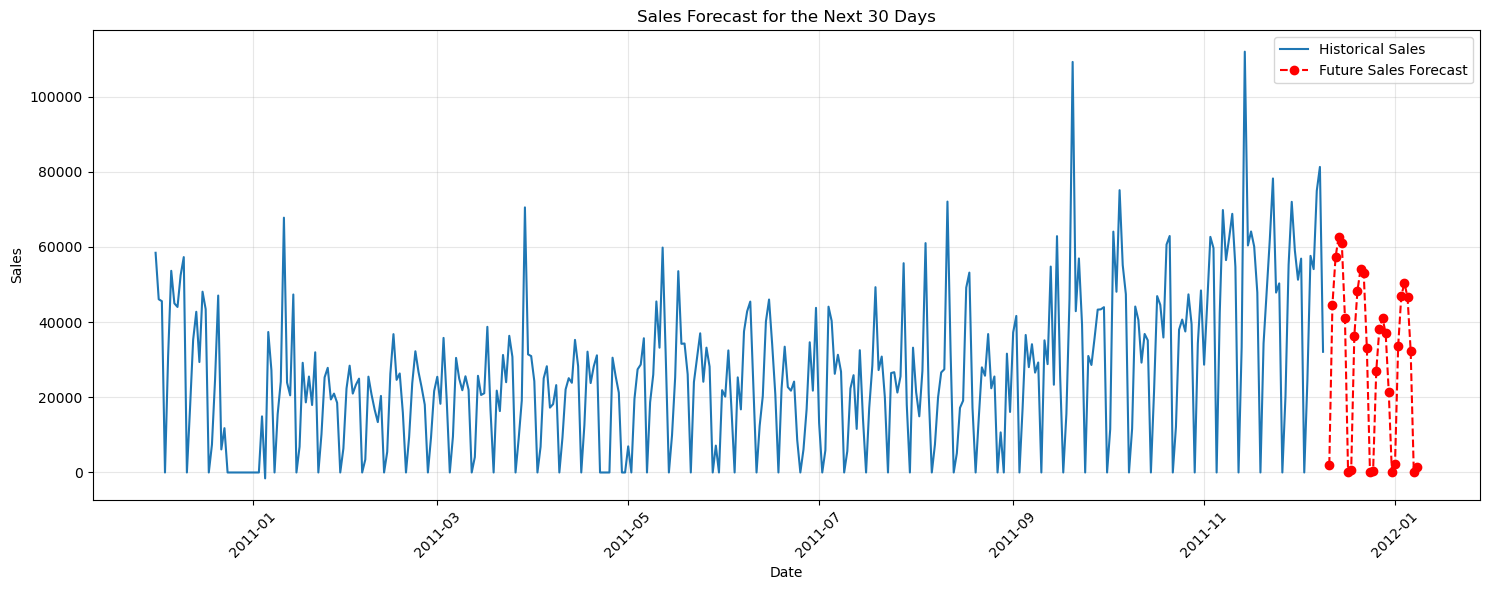

In [127]:
# Plot the actual sales and future sales forecast for the next 30 days
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales.index,
    daily_sales,
    label="Historical Sales"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Sales"],
    label="Future Sales Forecast",
    color="red",
    linestyle="--",
    marker="o"
)

plt.title("Sales Forecast for the Next 30 Days")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [128]:
# Print forecast summary
print("Forecast Summary")
print("-------------------------")

print("Total Forecast Sales:", future_forecast["Predicted_Sales"].sum())
print("Average Daily Sales:", future_forecast["Predicted_Sales"].mean())
print("Maximum Daily Sales:", future_forecast["Predicted_Sales"].max())
print("Minimum Daily Sales:", future_forecast["Predicted_Sales"].min())

print("Highest Sales Date:",
      future_forecast.loc[future_forecast["Predicted_Sales"].idxmax(), "Date"])

print("Lowest Sales Date:",
      future_forecast.loc[future_forecast["Predicted_Sales"].idxmin(), "Date"])

Forecast Summary
-------------------------
Total Forecast Sales: 873784.9290955822
Average Daily Sales: 30130.514796399388
Maximum Daily Sales: 62767.160966491945
Minimum Daily Sales: 0.0
Highest Sales Date: 2011-12-14 00:00:00
Lowest Sales Date: 2011-12-17 00:00:00


### Future Sales Forecasting Results

A Neural Network model was used to forecast future daily sales using Recursive Forecasting.

The model generated the following results for the forecast period:

- Total Forecast Sales: 873,784.93
- Average Daily Sales: 30,130.51
- Maximum Predicted Sales: 62,767.16
- Minimum Predicted Sales: 0

The forecast reflects historical sales patterns and assumes zero sales on Saturdays based on the observed dataset.

These predictions are estimates and should be interpreted with caution.

In [129]:
df_sales.to_csv("cleaned_sales_data.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [130]:
forecast_data.tail(30).rename("Predicted_Sales").reset_index().to_csv("future_forecast.csv", index=False)

print("Forecast dataset exported successfully!")

Forecast dataset exported successfully!
